# Figure 2 — unified dataset version 2



In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "plagnetplus").is_dir())
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "figures" / "final"
OUTPUT.mkdir(parents=True, exist_ok=True)

import os
import pandas as pd
from IPython.display import display
from plagnetplus.figures.dataset_composition import load_training_examples, plot_v2_composition, version_table

DATA_ROOT = Path(os.environ["PNP_DATA_ROOT"])
REFERENCE = ROOT / "results" / "reference" / "datasets"
v1_locations = pd.read_csv(REFERENCE / "v1_location_split_counts.csv")
v1_splits = pd.read_csv(REFERENCE / "v1_split_summary.csv")
v2_samples = pd.read_csv(REFERENCE / "v2_sample_composition.csv")

from IPython.display import Image as IPyImage, Markdown

def show_saved_figure(path):
    path = Path(path)
    display(Markdown(f"**Saved figure:** `{path}`"))
    display(IPyImage(filename=str(path)))


In [2]:
display(version_table(v1_locations, v2_samples).style.format({"V1 (%)": "{:.2f}", "V2 (%)": "{:.2f}"}))
display(v1_splits.rename(columns={"_split": "Split", "rows": "V1 images"}))
display(v2_samples.groupby("split", observed=True)["Images"].sum().rename("V2 images").to_frame())

,Location,V1 images,V2 images,Change,V1 (%),V2 (%)
0,Aegina,12344,12344,0,9.24,10.01
1,FCT,25614,21305,-4309,19.17,17.28
2,Methana,74024,68008,-6016,55.41,55.17
3,MtStHelens,3101,3101,0,2.32,2.52
4,Rumania,18506,18506,0,13.85,15.01


,Split,V1 images,volcanoes,unique_image_references
0,test,16988,5,16988
1,train,101682,5,101682
2,validation,14919,4,14919


,V2 images
split,
test,16988
train,91357
validation,14919


**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_02_unified_dataset_v2.png`

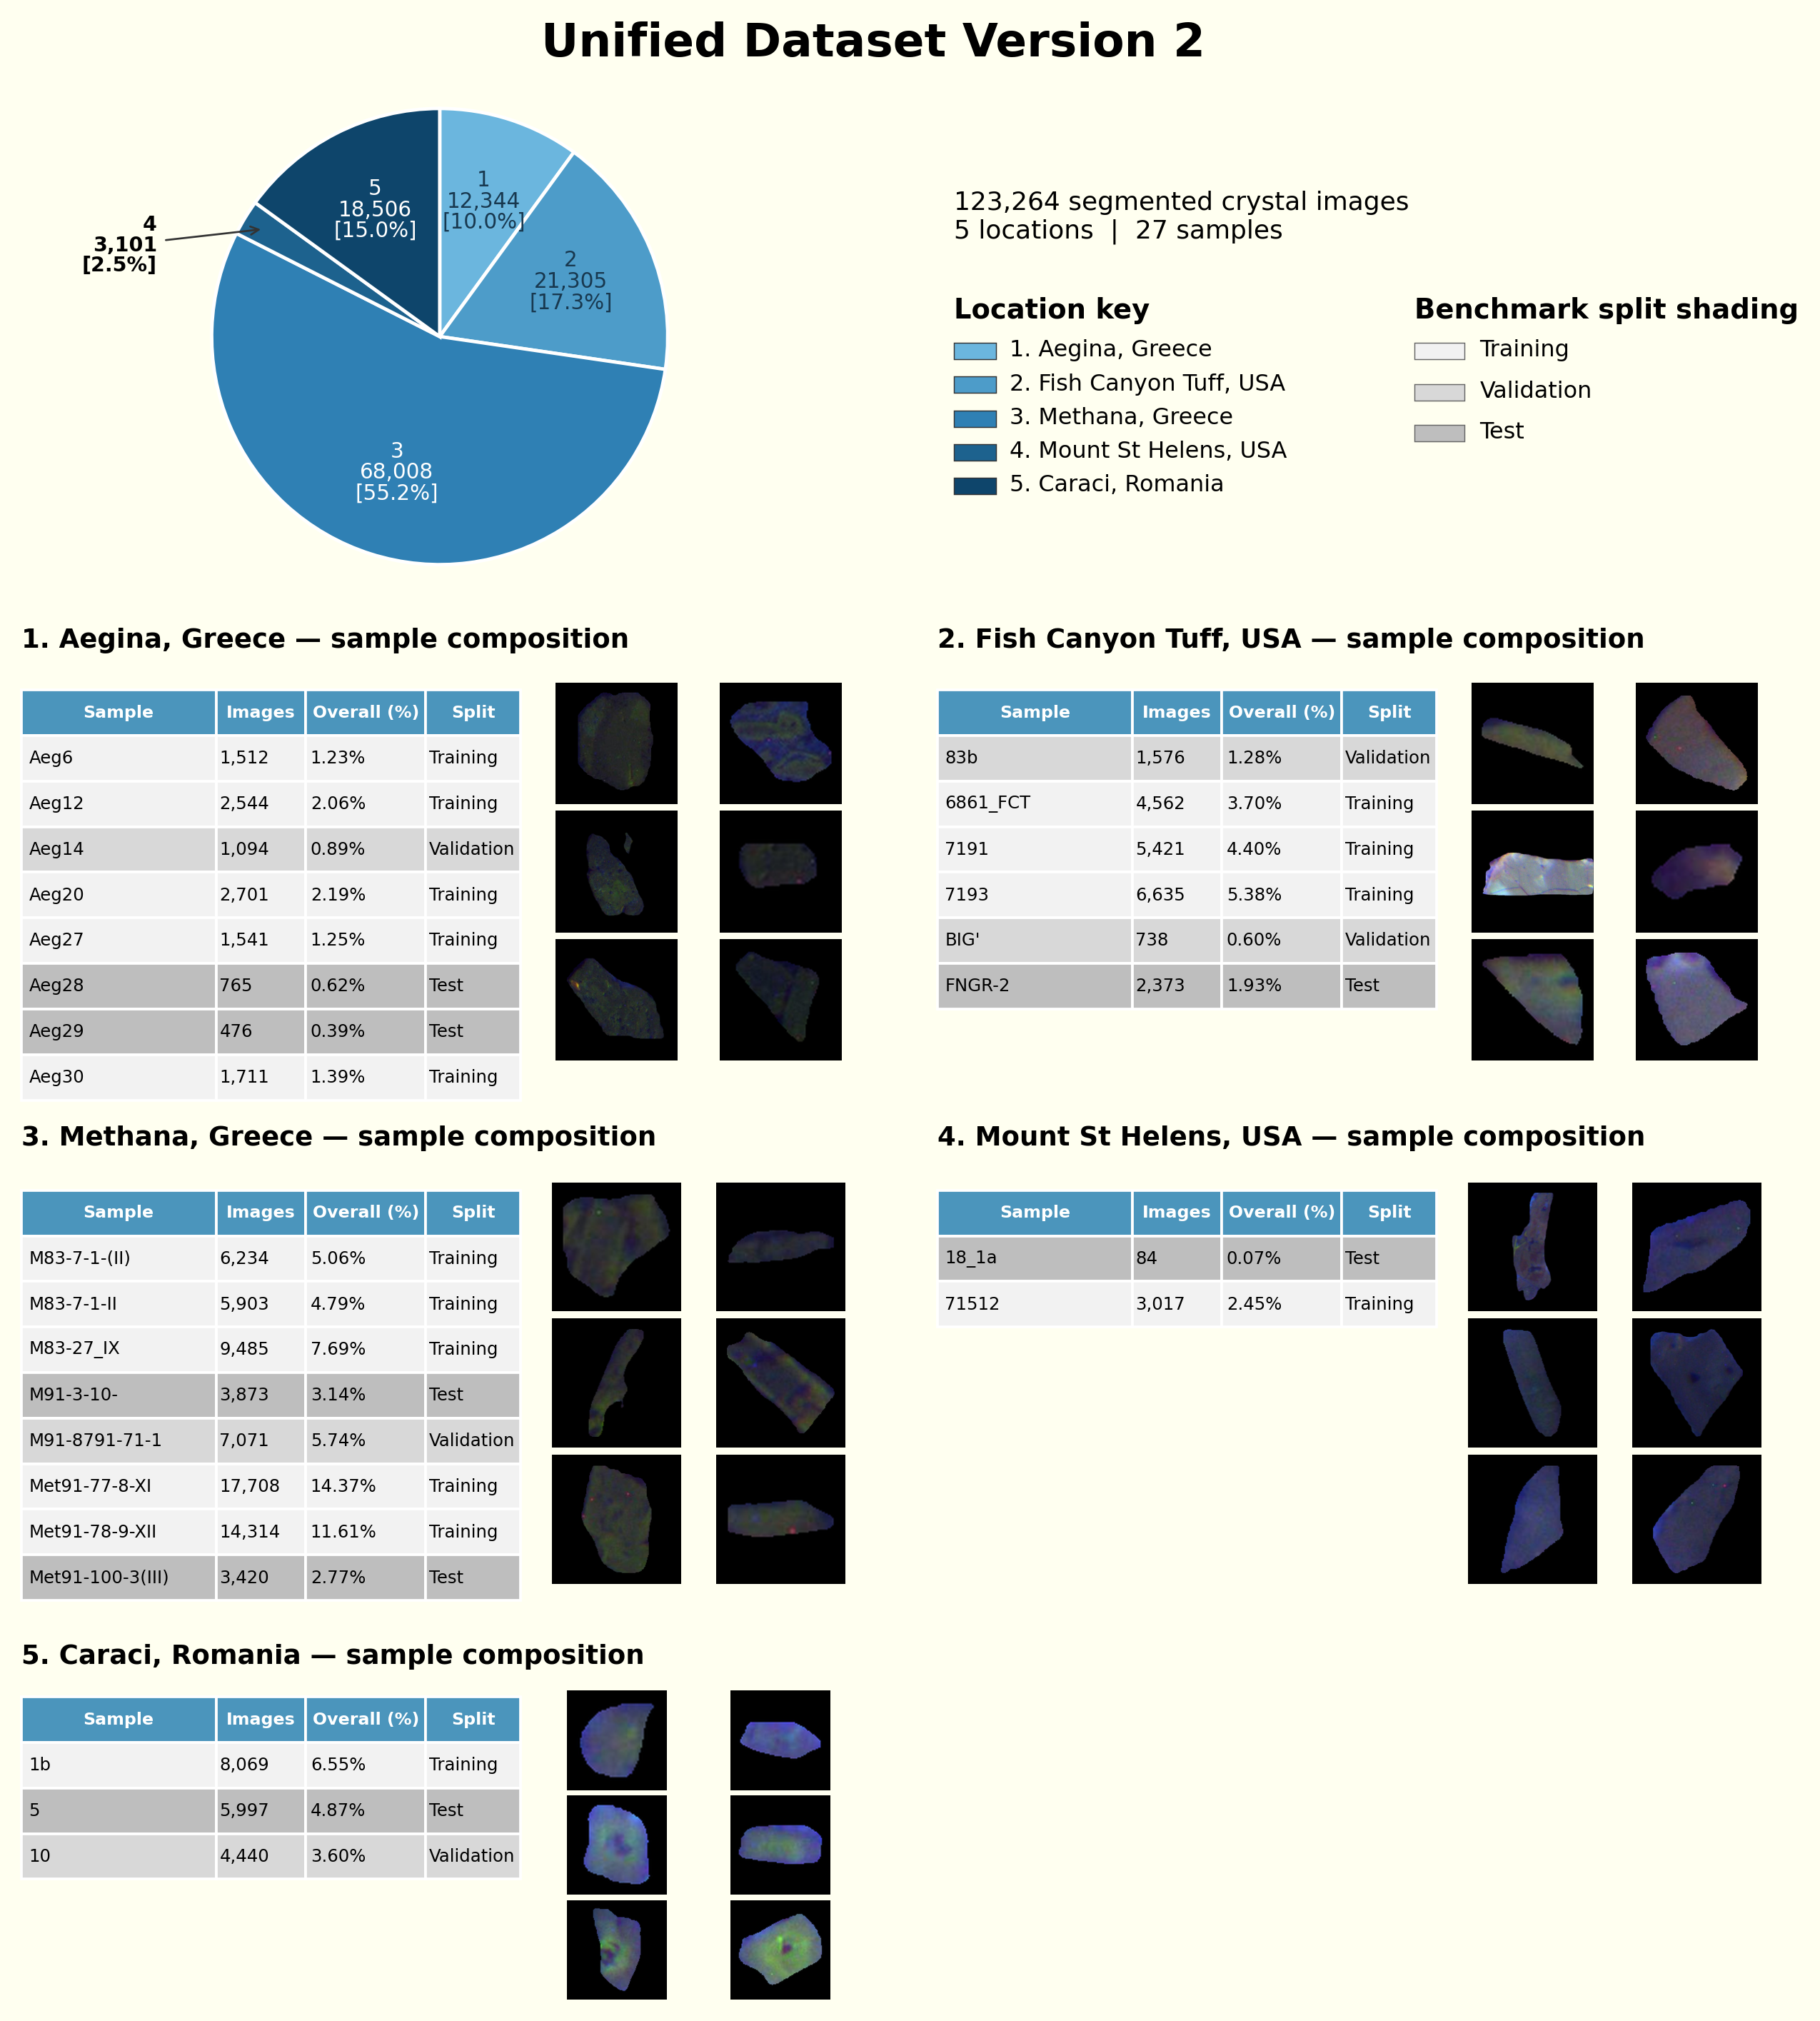

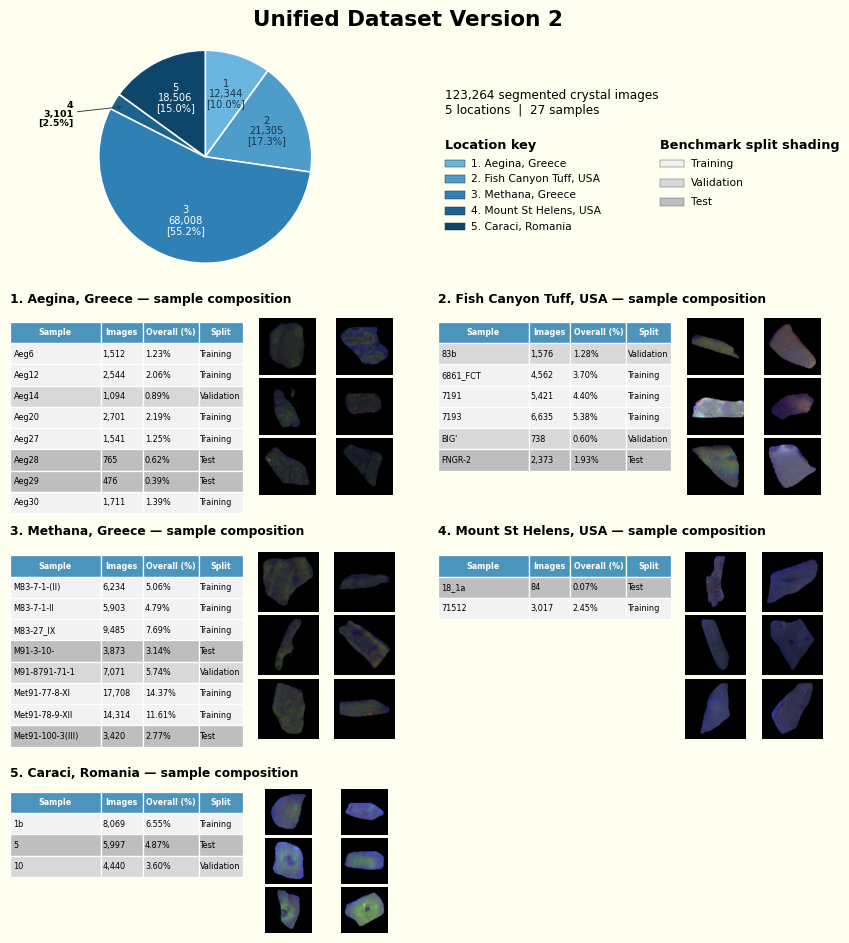

In [3]:
V2_ROOT = DATA_ROOT / "processed/plagnetplus/ssl_unified_v2"
BENCHMARK = V2_ROOT / "benchmarks/pooled_broad_p80_10_10_v2"
examples = load_training_examples(
    BENCHMARK / "manifests/crystals_all.csv",
    V2_ROOT / "metadata/image_root_map.json",
)
figure = plot_v2_composition(v2_samples, examples)
out_path = OUTPUT / "figure_02_unified_dataset_v2.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)
